# 20 - Petrophys for LLM agents (MCP)

**Part B - Petrophys Curriculum**

LLM applications such as Claude Desktop, Claude Code, Cursor and VS Code can call
tools through the **Model Context Protocol (MCP)**. Petrophys ships an MCP server, so a
model can load wells, run the interpretation, read the trace, summarize zones, plot
logs and export results - using exactly the validated workflow you have learned in
this course, never a re-implementation of the physics.

## Learning goals

- Start the Petrophys MCP server and see the tools a model is offered.
- Follow a complete agent session: load, interpret, explain, summarize, plot, export.
- See how the server keeps the model honest: validated settings, actionable errors,
  skip reasons and data-quality warnings in every answer.
- Connect a real MCP client to your own well folders.

## Why this matters

A language model is good at planning an analysis and explaining it, but it must not
invent petrophysics. With MCP the model *calls* Petrophys: every number it reports comes
from the same traced workflow as `pp.interpret`, every skipped step has a stated
reason, and every setting it passes is validated before anything runs. The server also
limits file access to folders you choose.

### Prerequisites

The MCP extra needs Python 3.10+: `pip install "petrophys[mcp]"`. Real clients start
the server as a separate process (`petrophys-mcp`); in this notebook we connect to it
in-process with the MCP Python client, which sends exactly the same requests.

## 1 - Start the server and list its tools

In [1]:
import json
from base64 import b64decode
from pathlib import Path

from IPython.display import Image, display
from mcp import Client

import petrophys as pp
from petrophys.mcp import create_server

print("petrophys", pp.__version__)

# The server keeps loaded wells and results; clients can connect and disconnect.
server = create_server(roots=["."])          # the folders the model may read and write

async with Client(server) as client:
    tools = (await client.list_tools()).tools
for tool in tools:
    print(f"{tool.name:26s} {tool.description.splitlines()[0]}")

petrophys 3.0.0
list_sample_wells          List the sample wells and input templates bundled with Petrophys.
interpretation_settings    Describe every interpretation setting: type, default, unit, accepted values.
load_well                  Load a well file and return its id, depth range, curves and header values.
load_sample_well           Load a bundled sample well (optionally with its formations and lithology).
list_loaded                List wells and interpretations held in this session.
describe_well              Return the header, depth range, curves (with units and coverage) and geology of a well.
curve_statistics           Summary statistics (valid count, min, P10, median, mean, P90, max) of curves in a depth window.
curve_values               Curve values versus depth in a window, decimated to at most max_points samples.
interpret_well             Run the full interpretation on a loaded well and summarize the result.
explain_step               Method, input and output curves, 

Each tool comes with a JSON schema whose parameters are described for the model. A
small helper calls a tool and returns its JSON result:

In [2]:
async def call_raw(tool, **arguments):
    async with Client(server) as client:
        return await client.call_tool(tool, arguments)


async def call(tool, **arguments):
    result = await call_raw(tool, **arguments)
    if result.is_error:
        raise RuntimeError(result.content[0].text)
    return result.structured_content


def show(data, limit=1500):
    text = json.dumps(data, indent=2)
    print(text if len(text) <= limit else text[:limit] + "\n...")


load_schema = next(tool for tool in tools if tool.name == "load_well").input_schema
show(load_schema["properties"])

{
  "path": {
    "description": "LAS, DLIS, CSV or TSV file; relative paths start at the first allowed folder.",
    "title": "Path",
    "type": "string"
  },
  "depth_unit": {
    "anyOf": [
      {
        "enum": [
          "m",
          "ft"
        ],
        "type": "string"
      },
      {
        "type": "null"
      }
    ],
    "default": null,
    "description": "Depth unit; required for CSV/TSV files.",
    "title": "Depth Unit"
  },
  "formations": {
    "anyOf": [
      {
        "type": "string"
      },
      {
        "type": "null"
      }
    ],
    "default": null,
    "description": "Optional formation tops/intervals file (CSV/Excel).",
    "title": "Formations"
  },
  "lithology": {
    "anyOf": [
      {
        "type": "string"
      },
      {
        "type": "null"
      }
    ],
    "default": null,
    "description": "Optional lithology intervals file (top, bottom, lithology).",
    "title": "Lithology"
  },
  "well_id": {
    "anyOf": [
      {
       

## 2 - What the model knows about settings

`interpretation_settings` lists every setting with its unit, default and accepted
values - the machine-readable form of `DynamicWorkflowConfig`.

In [3]:
settings = await call("interpretation_settings")
by_name = {item["name"]: item for item in settings["settings"]}
show({name: by_name[name] for name in ["rw", "bht_f", "sw_model"]})

{
  "rw": {
    "name": "rw",
    "type": "Optional[float]",
    "default": null,
    "description": "Formation water resistivity Rw, ohm.m, at rw_meas_temp_f."
  },
  "bht_f": {
    "name": "bht_f",
    "type": "Optional[float]",
    "default": null,
    "description": "Bottom-hole temperature, degF. Defaults to the LAS header BHT."
  },
  "sw_model": {
    "name": "sw_model",
    "type": "str",
    "default": "auto",
    "description": "\"auto\" (routed per sample by clay content) or one of \"archie\", \"simandoux\", \"indonesia\", \"dual_water\", \"waxman_smits\", \"north_sea\", \"nigeria_schlumberger\".",
    "choices": [
      "auto",
      "archie",
      "north_sea",
      "nigeria_schlumberger",
      "simandoux",
      "indonesia",
      "dual_water",
      "waxman_smits"
    ]
  }
}


## 3 - Load a well

In [4]:
well = await call("load_sample_well", name="30_6-5", with_geology=True)
print(well["well_id"], "|", well["name"], "|", well["header"]["field"])
print(f"{well['top']:.0f}-{well['bottom']:.0f} {well['depth_unit']}, {len(well['curves'])} curves")
print("formations:", well["formations"][:6], "...")
print([curve["mnemonic"] for curve in well["curves"]][:15])

30_6-5 | 30/6-5 | OSEBERG ØST
177-3556 m, 20 curves
formations: ['NORDLAND GP.', 'Utsira Fm.', 'HORDALAND GP.', 'ROGALAND GP.', 'Balder Fm.', 'Sele Fm.'] ...
['LITHOLOGY_GEOLINK', 'CALI', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'DTE', 'RDEP', 'SP', 'RSHA', 'RMED', 'BS', 'PHIC']


## 4 - Interpret

The model passes only what the logs cannot provide. Formation water resistivity is the
classic example: the server's instructions tell the model to ask the user for `rw`
rather than assume a value. Here we supply the study value of 0.07 ohm.m and ask for
key results over the Brent Group (2841-2958 m).

In [5]:
run = await call(
    "interpret_well",
    well_id="30_6-5",
    settings={"rw": 0.07},
    summary_top=2841,
    summary_bottom=2958,
)
show({key: run[key] for key in ["interpretation_id", "status", "resolved", "settings_used", "skipped_steps", "net_thickness"]})
for name, stats in run["key_results"].items():
    print(f"{name:5s} median {stats['median']:.3f} {stats['unit']}")

{
  "interpretation_id": "30_6-5/run-1",
  "status": "interpreted",
  "resolved": {
    "matrix_type": "sandstone",
    "lithology": "clastic"
  },
  "settings_used": {
    "rw": 0.07,
    "matrix_type": "sandstone",
    "lithology": "clastic",
    "formation_tops": "FormationTops(20 intervals)"
  },
  "skipped_steps": {
    "spectral_gamma": "Needs processed spectral gamma curves (potassium, thorium or uranium)",
    "elemental_spectroscopy": "Needs processed elemental concentration or yield curves",
    "hc_correction": "apply_hc_correction=False (hydrocarbon correction is opt-in)",
    "porosity_refinement": "No computed lithology log (LITHO) was produced to refine porosity by rock type"
  },
  "net_thickness": {
    "depth_unit": "m",
    "net_rock": 105.27385000020513,
    "net_res": 93.08585000018138,
    "net_pay": 83.03075000016179
  }
}
VCL   median 0.179 v/v
PHIT  median 0.203 v/v
PHIE  median 0.195 v/v
SW    median 0.448 frac
PERM  median 2044.582 mD


Every skipped step carries its reason, and the settings actually used - including the
matrix and lithology resolved from the data - are part of the answer.

## 5 - When the model gets it wrong

Invalid requests fail *before* anything runs, with a message the model can act on:

In [6]:
for tool, arguments in [
    ("interpret_well", {"well_id": "30_6-5", "settings": {"hc_type": "gass"}}),
    ("load_well", {"path": "/etc/passwd"}),
    ("explain_step", {"interpretation_id": "30_6-5/run-9", "step": "rw"}),
]:
    result = await call_raw(tool, **arguments)
    message = result.content[0].text.replace(str(Path.cwd()), ".")  # hide this machine's path
    print(f"{tool}: {message}\n")

interpret_well: Error executing tool interpret_well: Invalid DynamicWorkflowConfig:
  - hc_type='gass' is not valid; use one of: oil, gas (did you mean 'gas'?)

load_well: Error executing tool load_well: C:\etc\passwd is outside the folders this server may access ([home]\AppData\Local\Temp\petrophys-tutorial-ti2g3ioa). Start the server with --root <folder> or set PETROPHYS_MCP_ROOTS.

explain_step: Error executing tool explain_step: Unknown interpretation id '30_6-5/run-9'. Known interpretation ids: 30_6-5/run-1.



## 6 - Explain a result

`explain_step` returns the full trace record of one step - the method, the inputs, the
parameters and every decision - so the model can justify a number:

In [7]:
rw_step = await call("explain_step", interpretation_id=run["interpretation_id"], step="rw")
show({key: rw_step[key] for key in ["method", "parameters", "decisions"]})

{
  "method": "user_provided_assumed_reference_temperature",
  "parameters": {
    "rw": 0.07,
    "reference_temp_f": 75.0,
    "source_priority": "config.rw",
    "rw_min": 0.02155326279323719,
    "rw_max": 0.06794274403404314,
    "formation_temp_min_f": 77.47593503512317,
    "formation_temp_max_f": 258.8
  },
  "decisions": [
    "Rw input 0.0700 ohm.m used assumed reference temperature 75.0F and was directly corrected with Arps along the temperature profile"
  ]
}


## 7 - Summarize zones

In [8]:
brent = await call("summarize_zones", interpretation_id=run["interpretation_id"], top=2841, bottom=2958)
zone = brent["zones"][0]
print(f"Brent: gross {zone['gross_thickness']:.1f} m, net pay {zone['net_pay']:.1f} m, "
      f"avg PHIE {zone['avg_phie']:.3f}, avg Sw {zone['avg_sw']:.3f}")

by_formation = await call("summarize_zones", interpretation_id=run["interpretation_id"])
for row in by_formation["zones"]:
    if row["Net Pay (m)"]:
        print(f"{row['Formation']:15s} net pay {row['Net Pay (m)']:6.1f} m")

Brent: gross 117.0 m, net pay 83.1 m, avg PHIE 0.198, avg Sw 0.372
HORDALAND GP.   net pay  424.3 m
ROGALAND GP.    net pay   86.6 m
Balder Fm.      net pay   77.1 m
Sele Fm.        net pay    6.9 m
Lista Fm.       net pay    2.6 m
SHETLAND GP.    net pay   26.1 m
CROMER KNOLL GP. net pay    1.2 m
VIKING GP.      net pay   10.1 m
Draupne Fm.     net pay    9.1 m
Heather Fm.     net pay    0.9 m
BAAT GP.        net pay   83.1 m
Ness Fm.        net pay   14.3 m
Etive Fm.       net pay   68.7 m
DUNLIN GP.      net pay    2.3 m
Cook Fm.        net pay    2.3 m
Statfjord Fm.   net pay   53.9 m


## 8 - Plot

image/png


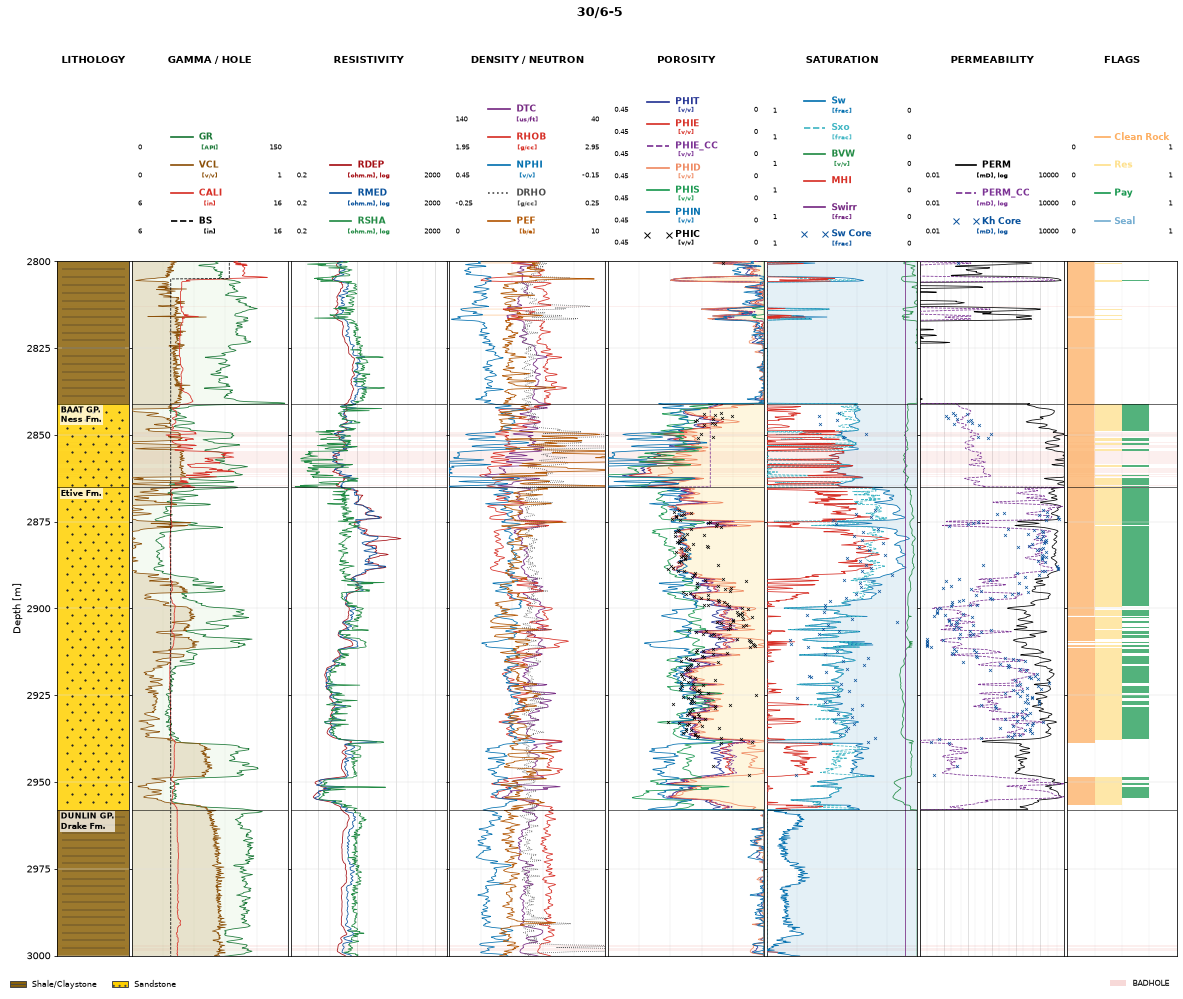

In [9]:
result = await call_raw(
    "plot_well", target_id=run["interpretation_id"], top=2800, bottom=3000, dpi=70
)
image = result.content[0]
print(image.mime_type)
display(Image(data=b64decode(image.data)))

## 9 - Export

In [10]:
exported = await call("export_results", interpretation_id=run["interpretation_id"], path="exports/30_6-5.las")
print(exported["format"], exported["bytes"], "bytes")

las 15930903 bytes


## 10 - Connect a real client

Install the extra and register the server with the folders that hold your wells:

```bash
pip install "petrophys[mcp]"
claude mcp add petrophys -- petrophys-mcp --root /path/to/wells
```

For Claude Desktop, Cursor or VS Code, add the same command and arguments to the
client's MCP configuration; see the [LLM agents guide](../../mcp.rst). Then ask, for
example: *"Load my_well.las, interpret it with Rw = 0.05 ohm.m at 75 degF, and tell me
the net pay in each formation - list any warnings."*

## Key takeaways

- The MCP server gives a model the Petrophys workflow, not a copy of it: results,
  traces and warnings are the ones `pp.interpret` produces.
- Settings are validated and errors are actionable, so a model can correct itself.
- File access is limited to the folders passed with `--root`.